This demonstration draws on scikit-learn's examples of [DBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_dbscan.html) and [HDBSCAN](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html).

In [1]:
%matplotlib inline

# DBSCAN Clustering

DBSCAN follows the density of the points. It has two settings: a distance ε (`eps`) and a minimum number of neighbors (`min_samples`, the slides' *v*, the point included).

- **Core point**: at least `min_samples` neighbors in its ε-neighborhood;
- **Border point**: not a core point, but a neighbor of one: it joins its cluster;
- **Noise**: neither.

A cluster expands step by step between neighboring core points.

The data is that of the slides' "DBSCAN — Example" figure: two interleaved moons ([`make_moons`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html)) and 15 points drawn at random over the plane. Clusters that aren't round, and noise: what k-means can't handle.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

# Two interleaved moons, and 15 points drawn at random over the plane
moons, moon_labels = make_moons(n_samples=300, noise=0.06, random_state=0)
rng = np.random.default_rng(0)
X = np.vstack([moons, rng.uniform((-1.3, -0.8), (2.3, 1.3), size=(15, 2))])


def count(labels):
  """Number of clusters and number of noise points (label -1)."""
  return len(set(labels) - {-1}), int(np.sum(labels == -1))


def show(ax, points, labels, title, core=None):
  """Core points filled, border points hollow, noise as crosses."""
  noise = labels == -1
  if core is None:
    core = ~noise
  border = ~core & ~noise
  ax.scatter(*points[core].T, s=12, c=labels[core], cmap="tab10", vmin=0, vmax=9)
  ax.scatter(
    *points[border].T,
    s=22,
    facecolors="white",
    edgecolors=plt.cm.tab10(labels[border]),
  )
  ax.scatter(*points[noise].T, s=25, marker="x", color="k")
  ax.set_title(title)
  ax.set_aspect("equal")
  ax.set_xticks([])
  ax.set_yticks([])

## K-means and DBSCAN Side by Side

K-means with k = 2, DBSCAN with ε = 0.2 and `min_samples=5` (choosing ε comes in the next part). The ARI compares the clusters with the two moons: 1 = identical partition, ≈ 0 = chance.

DBSCAN: 2 clusters, 10 noise points
303 core points, 2 border points
ARI on the moons: k-means 0.22, DBSCAN 1.00
Mean silhouette: k-means 0.48, DBSCAN 0.32 (without the noise)


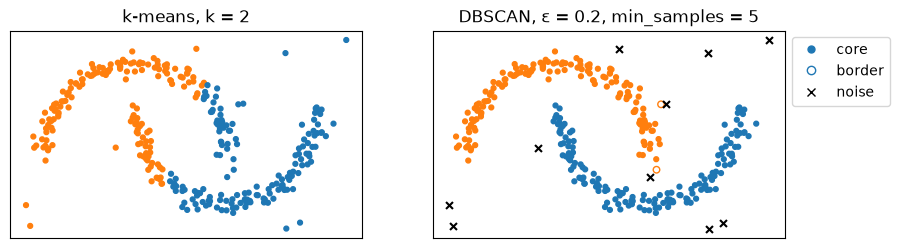

In [3]:
kmeans_labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)
dbscan = DBSCAN(eps=0.2, min_samples=5).fit(X)
labels = dbscan.labels_
is_core = np.zeros(len(X), dtype=bool)
is_core[dbscan.core_sample_indices_] = True

is_border = ~is_core & (labels != -1)
n_clusters, n_noise = count(labels)
print(f"DBSCAN: {n_clusters} clusters, {n_noise} noise points")
print(f"{is_core.sum()} core points, {is_border.sum()} border points")

# ARI on the 300 points of the moons, compared with the two moons
ari_kmeans = adjusted_rand_score(moon_labels, kmeans_labels[:300])
ari_dbscan = adjusted_rand_score(moon_labels, labels[:300])
print(f"ARI on the moons: k-means {ari_kmeans:.2f}, DBSCAN {ari_dbscan:.2f}")
kept = labels != -1
silhouette_kmeans = silhouette_score(X, kmeans_labels)
silhouette_dbscan = silhouette_score(X[kept], labels[kept])
print(f"Mean silhouette: k-means {silhouette_kmeans:.2f}, ", end="")
print(f"DBSCAN {silhouette_dbscan:.2f} (without the noise)")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5))
show(left, X, kmeans_labels, "k-means, k = 2")
show(right, X, labels, "DBSCAN, ε = 0.2, min_samples = 5", core=is_core)
right.legend(
  handles=[
    plt.Line2D([], [], marker="o", ls="", color="C0", markersize=5, label="core"),
    plt.Line2D(
      [], [], marker="o", ls="", mfc="white", mec="C0", markersize=6, label="border"
    ),
    plt.Line2D([], [], marker="x", ls="", color="k", label="noise"),
  ],
  loc="upper left",
  bbox_to_anchor=(1, 1),
)
plt.show()

K-means cuts the moons into two halves (ARI 0.22): it looks for round groups around centroids, and each boundary is halfway between two centroids. DBSCAN follows the density: it finds the two moons (ARI 1.00) and marks as noise 10 of the 15 added points (the other 5 fell on a moon).

The mean silhouette still prefers k-means (0.48 against 0.32): it favors round, compact clusters. It is one clue among others.

## Choosing ε: the k-distance Plot

For each point, the distance to its 5th neighbor (5 = `min_samples`, the point counted among its neighbors as in DBSCAN), sorted. In dense areas, this distance is small; for the noise, it is large. Take ε at the elbow, where the curve turns up.

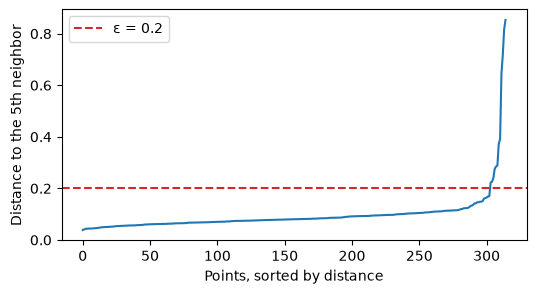

In [4]:
# Distance of each point to its 5th neighbor, itself included (as min_samples)
neighbors = NearestNeighbors(n_neighbors=5).fit(X)
distances = np.sort(neighbors.kneighbors(X)[0][:, -1])

plt.figure(figsize=(6, 3))
plt.plot(distances)
plt.axhline(0.2, color="C3", ls="--", label="ε = 0.2")
plt.xlabel("Points, sorted by distance")
plt.ylabel("Distance to the 5th neighbor")
plt.legend()
plt.show()

Three values of ε around the elbow:

ε = 0.1: 11 cluster(s), 29 noise points
ε = 0.2: 2 cluster(s), 10 noise points
ε = 0.3: 1 cluster(s), 6 noise points


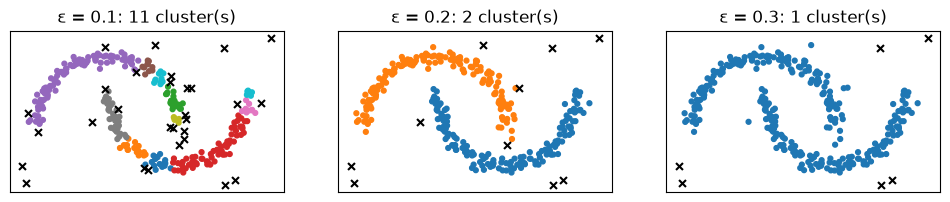

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, eps in zip(axes, (0.1, 0.2, 0.3)):
  labels = DBSCAN(eps=eps, min_samples=5).fit(X).labels_
  n_clusters, n_noise = count(labels)
  print(f"ε = {eps}: {n_clusters} cluster(s), {n_noise} noise points")
  show(ax, X, labels, f"ε = {eps}: {n_clusters} cluster(s)")
plt.show()

ε too small (0.1): the moons break up into 11 clusters, with 29 noise points. ε too large (0.3): the two moons merge into a single cluster. At the elbow, ε = 0.2 separates them.

## HDBSCAN

[HDBSCAN](https://scikit-learn.org/stable/modules/clustering.html#hdbscan) (`sklearn.cluster.HDBSCAN`, scikit-learn ≥ 1.3) is DBSCAN over every value of ε: it keeps the clusters that last longest as ε varies. No ε to set, varying densities, and a single setting: the minimum cluster size (`min_cluster_size`).

On the moons, without ε:

In [6]:
# copy=True: HDBSCAN doesn't modify X (the default from scikit-learn 1.10)
labels = HDBSCAN(min_cluster_size=10, copy=True).fit(X).labels_
n_clusters, n_noise = count(labels)
print(f"HDBSCAN: {n_clusters} clusters, {n_noise} noise points, ", end="")
print(f"ARI on the moons {adjusted_rand_score(moon_labels, labels[:300]):.2f}")

HDBSCAN: 2 clusters, 11 noise points, ARI on the moons 0.99


On four groups of very different densities, two tight and close, two diffuse (the dataset of the "Multi-Scale Clustering" part of scikit-learn's [Demo of HDBSCAN clustering algorithm](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html) page), a single ε does not fit every cluster:

DBSCAN, ε = 0.2: 9 clusters, 342 noise points, ARI 0.65
DBSCAN, ε = 0.8: 3 clusters, 14 noise points, ARI 0.66
HDBSCAN, min_cluster_size = 20: 4 clusters, 80 noise points, ARI 0.84


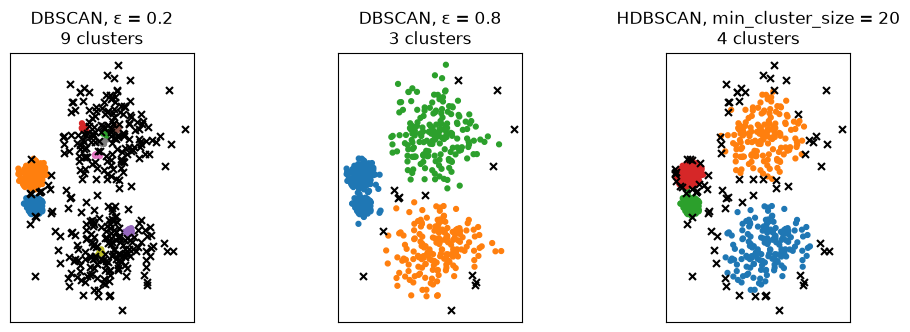

In [7]:
blobs, blob_labels = make_blobs(
  n_samples=750,
  centers=[[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]],
  cluster_std=[0.2, 0.35, 1.35, 1.35],
  random_state=0,
)
models = {
  "DBSCAN, ε = 0.2": DBSCAN(eps=0.2, min_samples=5),
  "DBSCAN, ε = 0.8": DBSCAN(eps=0.8, min_samples=5),
  "HDBSCAN, min_cluster_size = 20": HDBSCAN(min_cluster_size=20, copy=True),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (title, model) in zip(axes, models.items()):
  labels = model.fit(blobs).labels_
  n_clusters, n_noise = count(labels)
  ari = adjusted_rand_score(blob_labels, labels)
  print(f"{title}: {n_clusters} clusters, {n_noise} noise points, ARI {ari:.2f}")
  show(ax, blobs, labels, f"{title}\n{n_clusters} clusters")
plt.show()

In [8]:
# DBSCAN's best ε, chosen knowing the original groups
eps_values = np.arange(0.05, 1.5, 0.05)
aris = [
  adjusted_rand_score(blob_labels, DBSCAN(eps=eps, min_samples=5).fit(blobs).labels_)
  for eps in eps_values
]
best = np.argmax(aris)
print(f"Best DBSCAN: ε = {eps_values[best]:.2f}, ARI {aris[best]:.2f}")
for size in (10, 40):
  labels = HDBSCAN(min_cluster_size=size, copy=True).fit(blobs).labels_
  n_clusters, n_noise = count(labels)
  ari = adjusted_rand_score(blob_labels, labels)
  print(
    f"HDBSCAN, min_cluster_size = {size}: {n_clusters} clusters, "
    f"{n_noise} noise points, ARI {ari:.2f}"
  )

Best DBSCAN: ε = 0.85, ARI 0.67
HDBSCAN, min_cluster_size = 10: 4 clusters, 55 noise points, ARI 0.89
HDBSCAN, min_cluster_size = 40: 4 clusters, 127 noise points, ARI 0.76


With ε = 0.2, the two tight groups are separated, but the two diffuse groups break up (9 clusters, 342 noise points); with ε = 0.8, the diffuse groups are found, but the two tight groups merge (3 clusters). Even chosen knowing the original groups, the best ε (0.85) gets no higher than an ARI of 0.67. HDBSCAN finds the 4 groups (ARI 0.84), and keeps them for a minimum size from 10 to 40: a setting that matters little. It puts the scattered points of the diffuse groups in the noise, the more so as the minimum size grows, which lowers its ARI (from 0.89 to 0.76).